In [ ]:
import pandas as pd
print(pd.__version__)

2.3.3


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/Dataset.csv')
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [ ]:
print(df.shape)
df.info()

(8790, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [ ]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [ ]:
print((df['director'] == 'Not Given').sum())
print((df['country'] == 'Not Given').sum())

2588
287


In [ ]:
print(df.duplicated().sum())
print(df['title'].duplicated().sum())
df[df['title'].duplicated(keep=False)][['title', 'type', 'release_year']]

0
3


,title,type,release_year
393,9-Feb,TV Show,2018
537,9-Feb,TV Show,2018
2925,15-Aug,Movie,2019
3285,22-Jul,Movie,2018
4260,22-Jul,Movie,2018
4261,15-Aug,Movie,2019


In [ ]:
df = df.drop_duplicates(subset=['title', 'type', 'release_year']).reset_index(drop=True)
df = df.replace('Not Given', '')
print(df.shape)

(8787, 10)


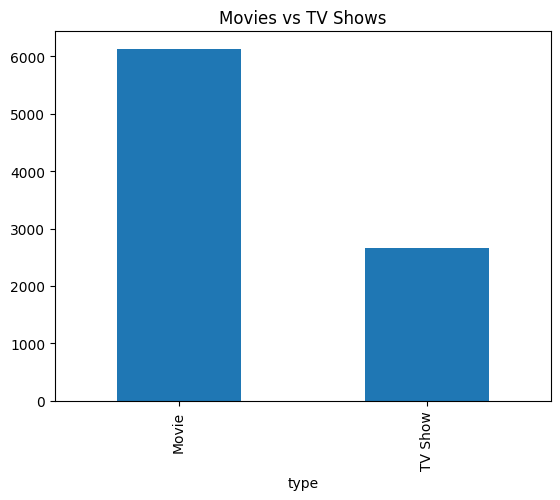

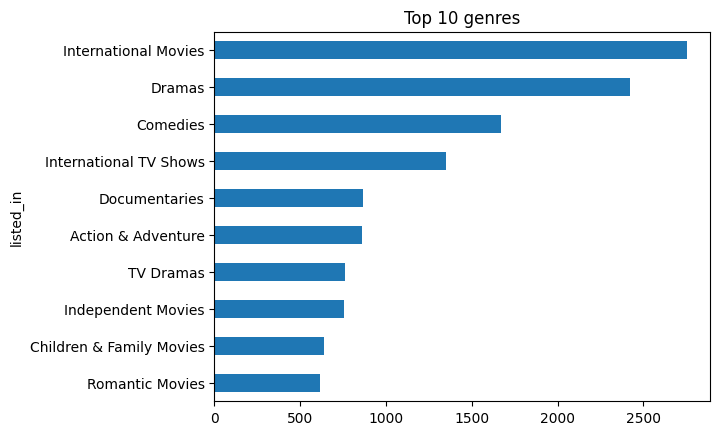

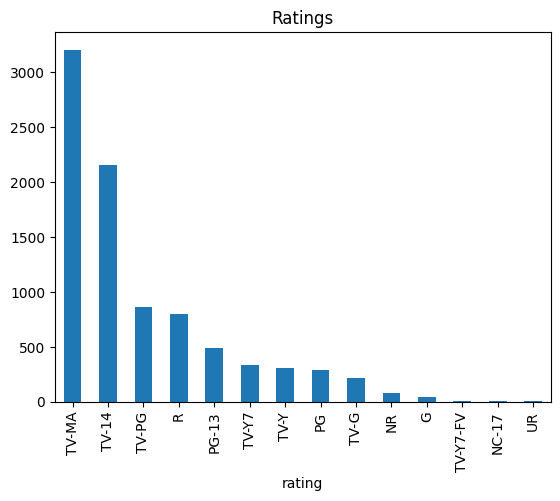

In [ ]:
df['type'].value_counts().plot(kind='bar', title='Movies vs TV Shows')
plt.savefig('../screenshots/01_type_split.png', bbox_inches='tight')
plt.show()

genres = df['listed_in'].str.split(', ').explode()
genres.value_counts().head(10).plot(kind='barh', title='Top 10 genres')
plt.gca().invert_yaxis()
plt.savefig('../screenshots/02_top_genres.png', bbox_inches='tight')
plt.show()

df['rating'].value_counts().plot(kind='bar', title='Ratings')
plt.savefig('../screenshots/03_ratings.png', bbox_inches='tight')
plt.show()

In [ ]:
raw = pd.read_csv('../data/Dataset.csv')
raw['director'].value_counts().head(3)

director
Not Given              2588
Rajiv Chilaka            20
Alastair Fothergill      18
Name: count, dtype: int64

**1. Why did isnull().sum() show zero missing values when many directors are missing?**
The file stores unknown directors as the text "Not Given" instead of leaving them empty. isnull() only counts empty values, so it didn't count these. There are 2588 of them for director.

In [ ]:
print(df['listed_in'].head(3))
print(df['listed_in'].str.split(', ').head(3))
print(df['listed_in'].value_counts().head(3))
print(genres.value_counts().head(3))

0                                        Documentaries
1    Crime TV Shows, International TV Shows, TV Act...
2                   TV Dramas, TV Horror, TV Mysteries
Name: listed_in, dtype: object
0                                      [Documentaries]
1    [Crime TV Shows, International TV Shows, TV Ac...
2                 [TV Dramas, TV Horror, TV Mysteries]
Name: listed_in, dtype: object
listed_in
Dramas, International Movies    362
Documentaries                   359
Stand-Up Comedy                 334
Name: count, dtype: int64
listed_in
International Movies    2752
Dramas                  2424
Comedies                1673
Name: count, dtype: int64


**2. Why do we split listed_in before counting genres?**
Each title has several genres stored together in one string, like "Dramas, International Movies". If I count the whole strings, a combination counts as one "genre" and the totals are split up across many combinations. For example, "Dramas, International Movies" only showed 362, while "Dramas" on its own appears 2,424 times once the genres are split. Splitting gives one genre per row, so each genre is counted correctly.

**3. How many duplicate titles did I remove?**
I removed 3 rows. The data had 8790 rows before cleaning and 8787 after. The repeated titles were 9-Feb, 15-Aug and 22-Jul.

In [ ]:
df['decade'] = 'decade' + (df['release_year'] // 10 * 10).astype(str)

def tokens(s):
    return ' '.join(p.strip().lower().replace(' ', '_') for p in s.split(',') if p.strip())

def make_soup(data, use=('genres', 'type', 'country', 'director', 'decade', 'rating')):
    soup = pd.Series([''] * len(data), index=data.index)
    if 'genres' in use:
        soup = soup + ' ' + data['listed_in'].apply(tokens) + ' ' + data['listed_in'].apply(tokens)
    if 'type' in use:
        soup = soup + ' ' + data['type'].str.lower().str.replace(' ', '_')
    if 'country' in use:
        soup = soup + ' ' + data['country'].apply(tokens)
    if 'director' in use:
        soup = soup + ' ' + data['director'].apply(tokens)
    if 'decade' in use:
        soup = soup + ' ' + data['decade']
    if 'rating' in use:
        soup = soup + ' ' + data['rating'].str.lower()
    return soup

df['soup'] = make_soup(df)
df[['title', 'soup']].head()

,title,soup
0,Dick Johnson Is Dead,documentaries documentaries movie united_stat...
1,Ganglands,crime_tv_shows international_tv_shows tv_acti...
2,Midnight Mass,tv_dramas tv_horror tv_mysteries tv_dramas tv...
3,Confessions of an Invisible Girl,children_&_family_movies comedies children_&_...
4,Sankofa,dramas independent_movies international_movie...


## Phase 3 notes

**1. What do the two numbers in matrix.shape mean?**
The shape is (8787, 5140). There are 8787 titles (rows) and 5140 distinct words (columns) across all the soups.

**2. Why are genres added twice in the soup?**
So genre counts for more than the other features when titles are compared, because genre is the best sign that two titles are alike.

**3. Why do we write united_states instead of united states?**
The underscore keeps a multi-word name together as one feature. Without it, "United States" would be split into "united" and "states", which would be counted as two unrelated words. The same applies to names like kirsten_johnson, which my output showed as a single feature with the highest weight.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(token_pattern=r'\S+')
matrix = tfidf.fit_transform(df['soup'])
print(matrix.shape)

(8787, 5140)


In [ ]:
from sklearn.metrics.pairwise import linear_kernel

indices = pd.Series(df.index, index=df['title'].str.lower())
indices = indices[~indices.index.duplicated()]

In [ ]:
i = 0
row = matrix[i].toarray().flatten()
names = tfidf.get_feature_names_out()
top = row.argsort()[::-1][:8]
print(df.loc[i, 'title'])
for j in top:
    print(names[j], round(row[j], 3))

Dick Johnson Is Dead
kirsten_johnson 0.741
documentaries 0.523
pg-13 0.307
decade2020 0.216
united_states 0.158
movie 0.107
éric_warin 0.0
a._l._vijay 0.0


In [ ]:
def recommend(title, n=10, mat=None):
    mat = matrix if mat is None else mat
    idx = indices.get(title.lower())
    if idx is None:
        return f"'{title}' not found in the dataset."
    scores = linear_kernel(mat[idx], mat).flatten()
    order = np.argsort(-scores, kind='stable')
    top = [j for j in order if j != idx][:n]
    result = df.loc[top, ['title', 'type', 'listed_in', 'rating', 'release_year']].copy()
    result['score'] = scores[top].round(3)
    return result

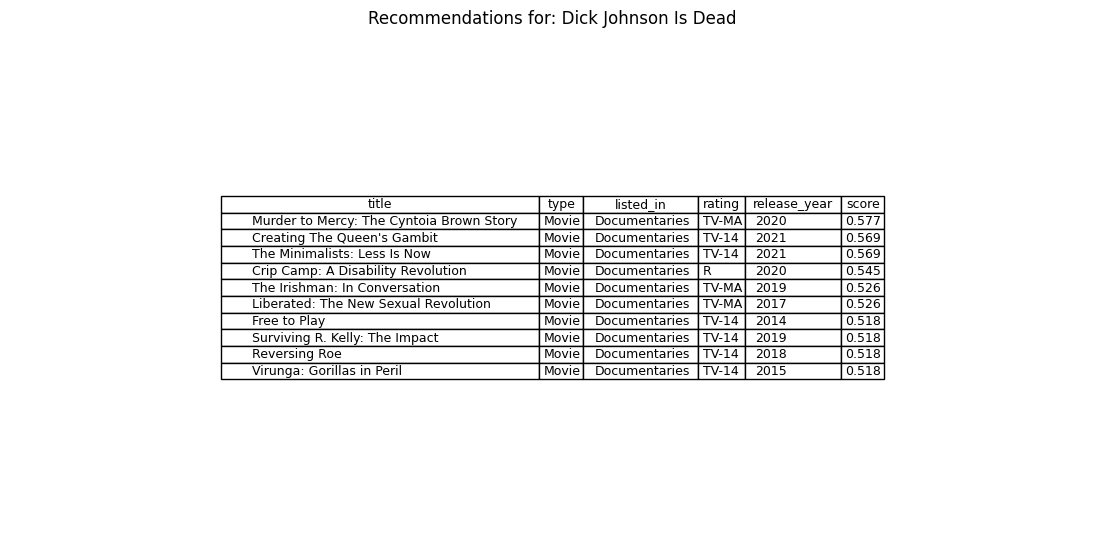

,title,type,listed_in,rating,release_year,score
7265,Murder to Mercy: The Cyntoia Brown Story,Movie,Documentaries,TV-MA,2020,0.577
6903,Creating The Queen's Gambit,Movie,Documentaries,TV-14,2021,0.569
6919,The Minimalists: Less Is Now,Movie,Documentaries,TV-14,2021,0.569
7308,Crip Camp: A Disability Revolution,Movie,Documentaries,R,2020,0.545
7437,The Irishman: In Conversation,Movie,Documentaries,TV-MA,2019,0.526
8046,Liberated: The New Sexual Revolution,Movie,Documentaries,TV-MA,2017,0.526
6786,Free to Play,Movie,Documentaries,TV-14,2014,0.518
7289,Surviving R. Kelly: The Impact,Movie,Documentaries,TV-14,2019,0.518
7936,Reversing Roe,Movie,Documentaries,TV-14,2018,0.518
8310,Virunga: Gorillas in Peril,Movie,Documentaries,TV-14,2015,0.518


In [ ]:
import re

def save_table(table, filename, title=''):
    if isinstance(table, str):          # "not found" message
        print(table)
        return
    fig, ax = plt.subplots(figsize=(14, 0.5 * len(table) + 1.5))
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=12, pad=10)
    t = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='left')
    t.auto_set_font_size(False)
    t.set_fontsize(9)
    t.auto_set_column_width(list(range(len(table.columns))))
    plt.savefig(f'../screenshots/{filename}', bbox_inches='tight', dpi=150)
    plt.show()

def show_and_save(title):
    result = recommend(title)
    name = re.sub(r'[^a-z0-9]+', '_', title.lower()).strip('_')
    save_table(result, f'04_recommend_{name}.png', f'Recommendations for: {title}')
    return result

show_and_save('Dick Johnson Is Dead')

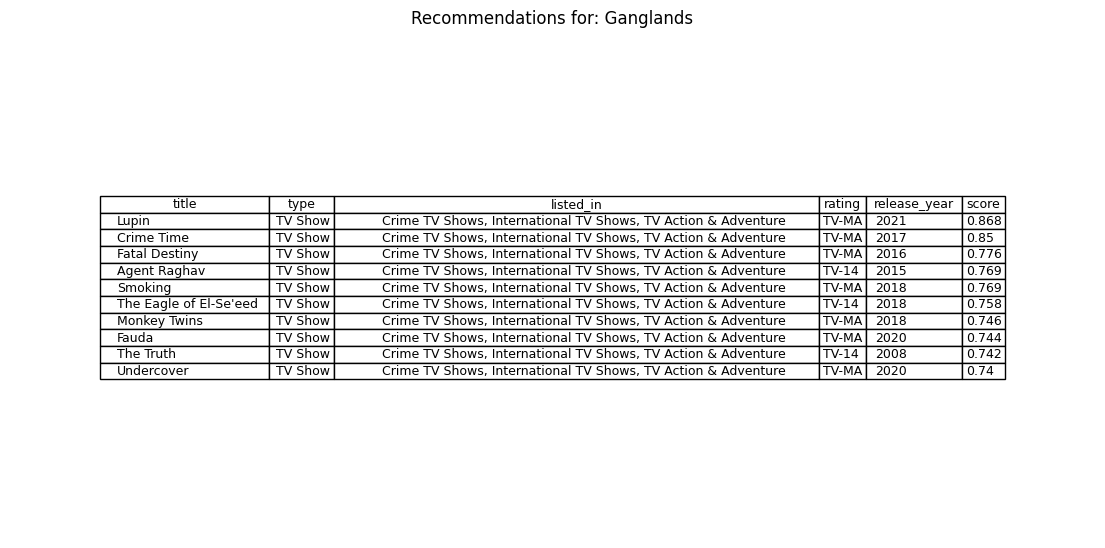

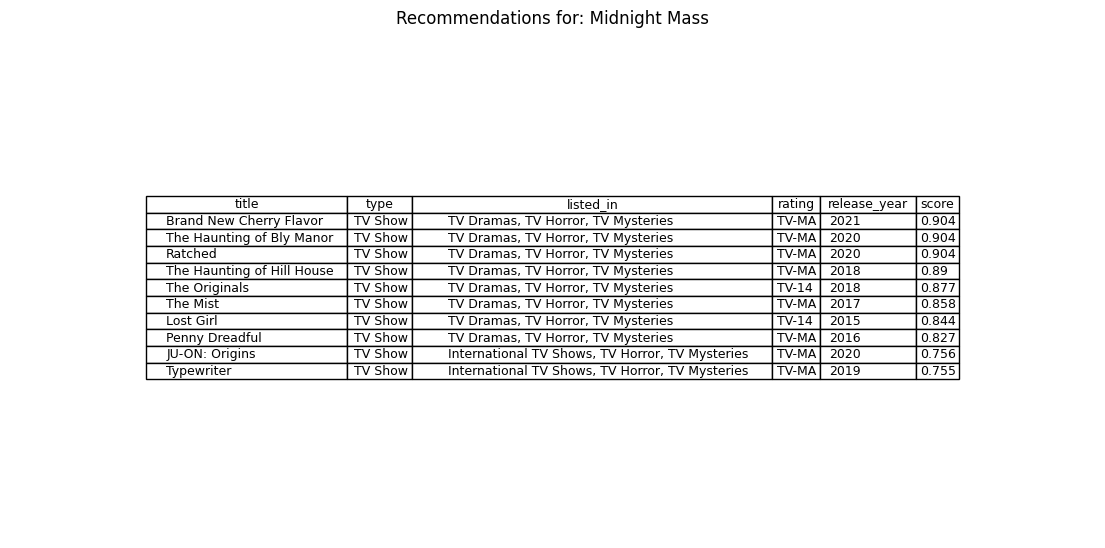

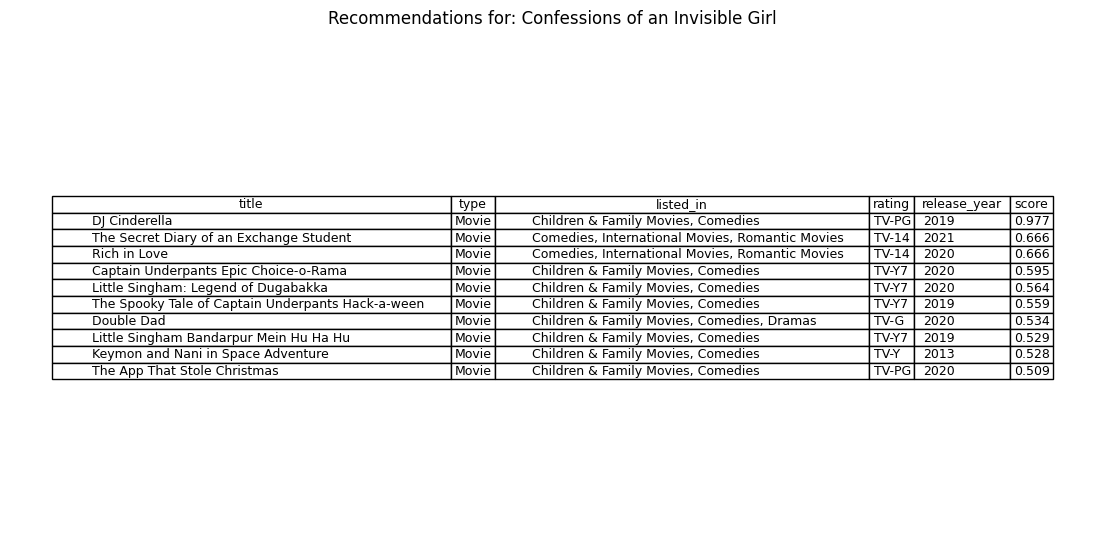

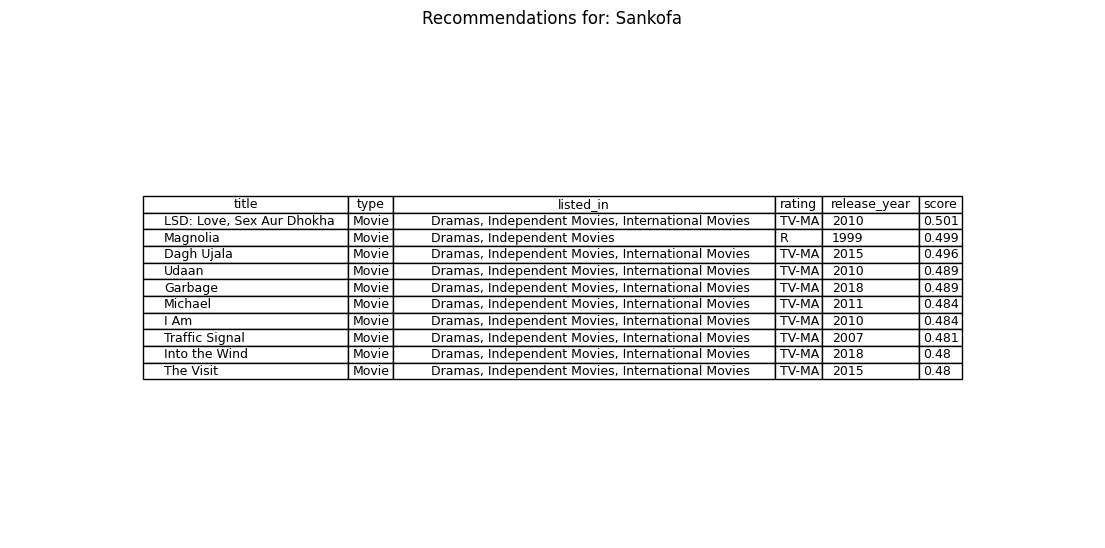

In [ ]:
for t in ['Ganglands', 'Midnight Mass', 'Confessions of an Invisible Girl', 'Sankofa']:
    show_and_save(t)

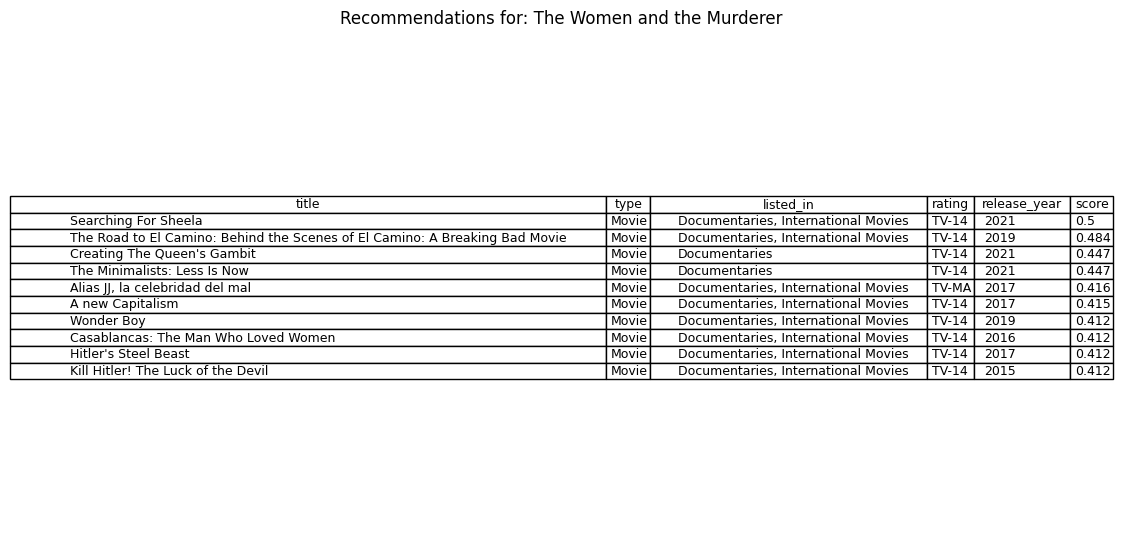

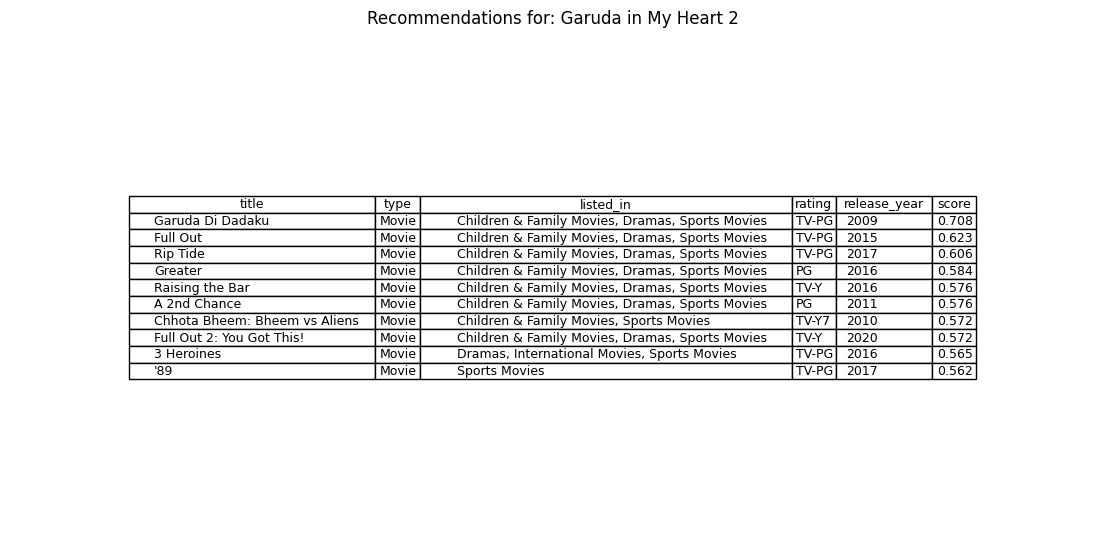

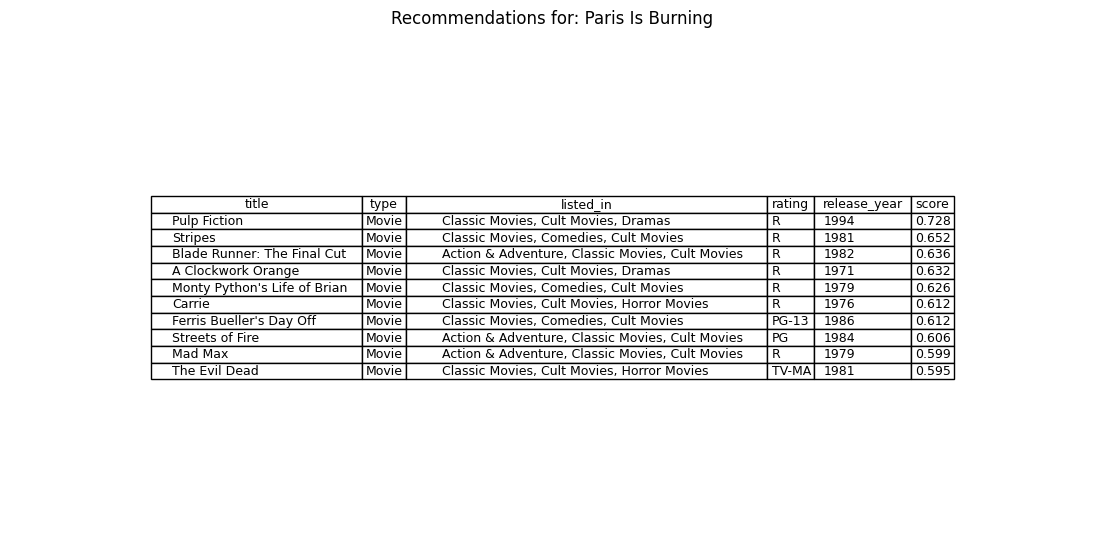

In [ ]:
for t in df['title'].sample(3, random_state=7):
    show_and_save(t)

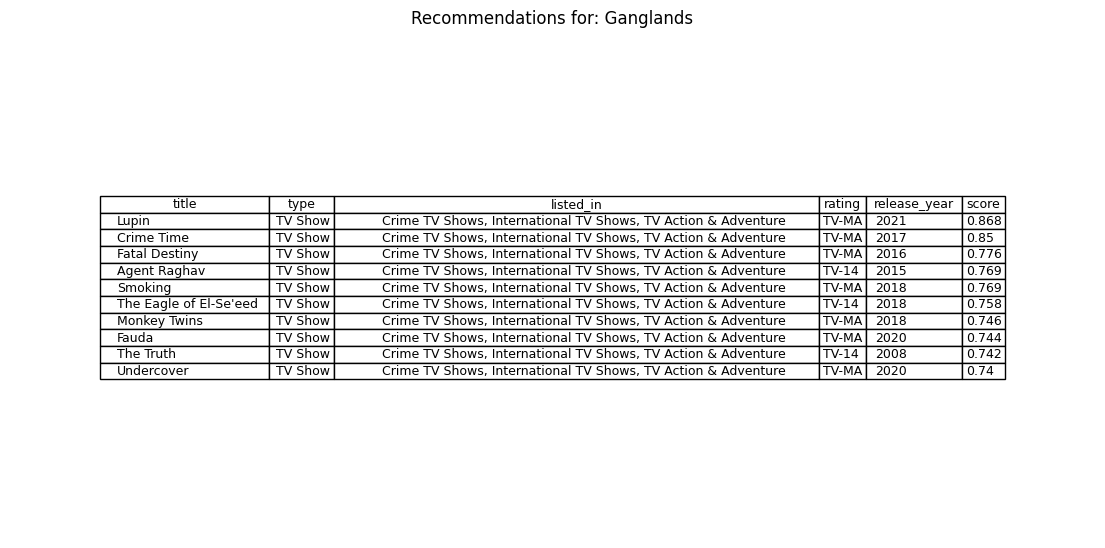

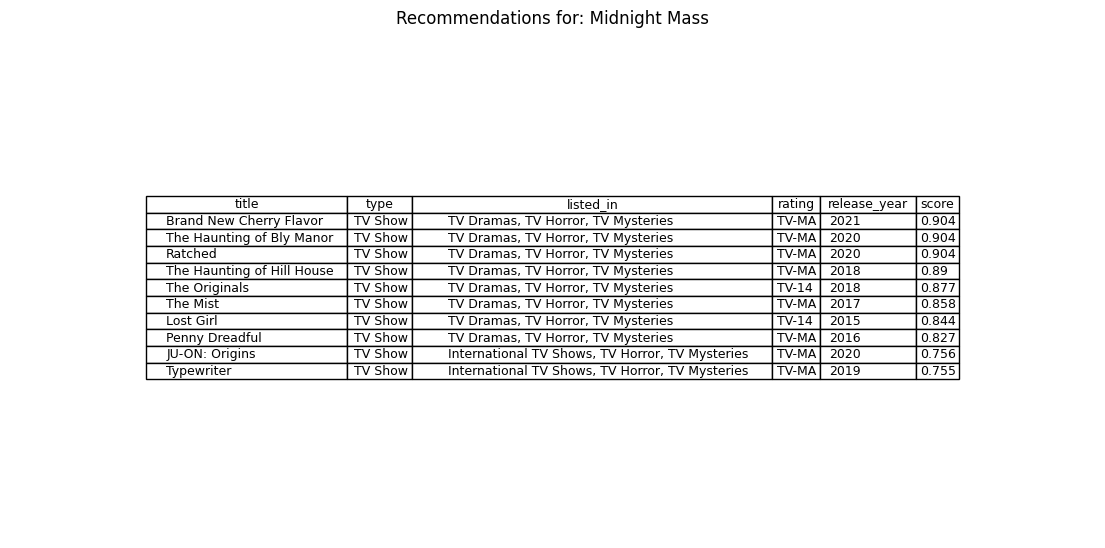

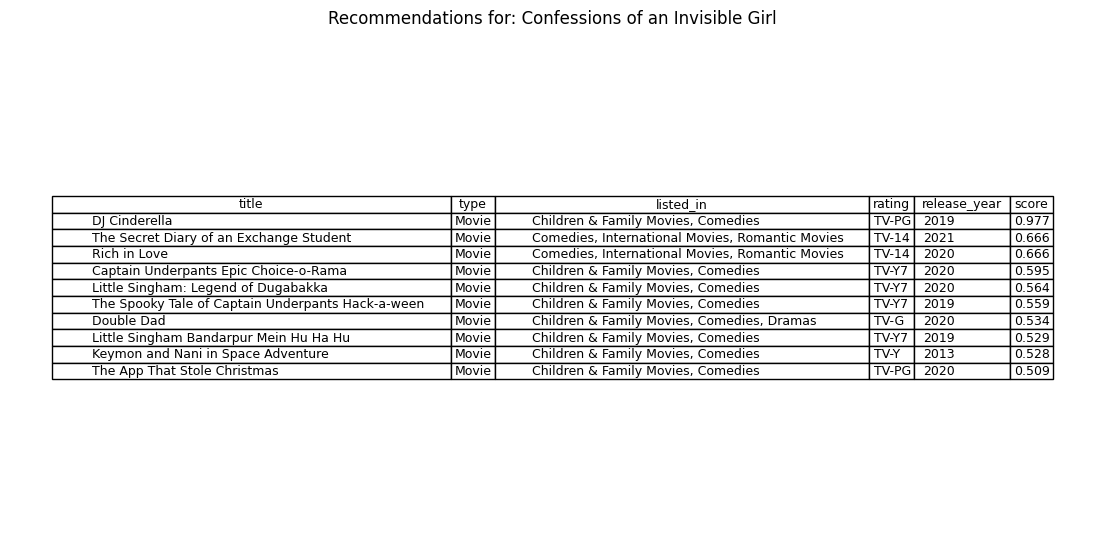

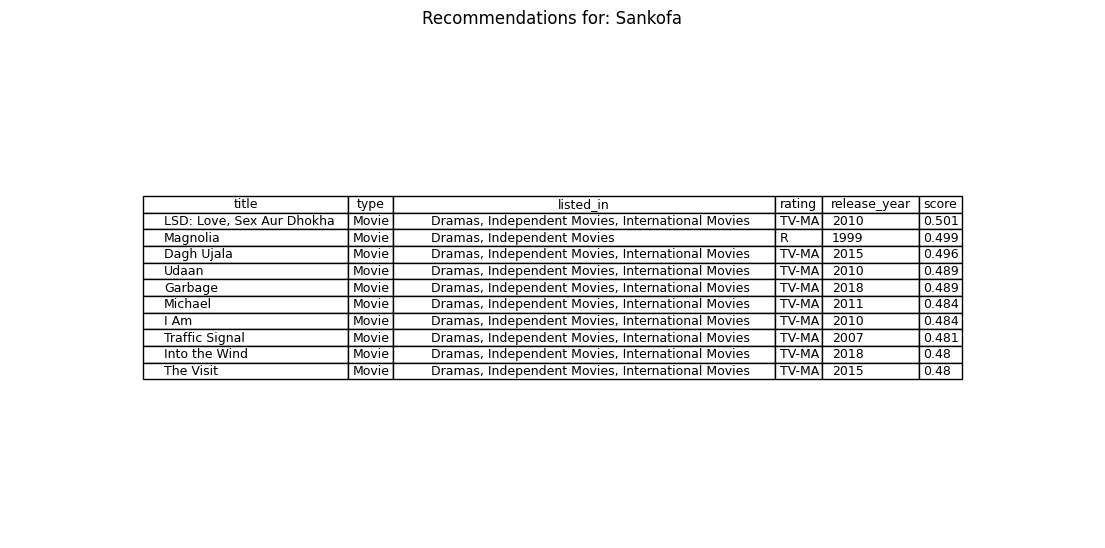

In [ ]:
for t in ['Ganglands', 'Midnight Mass', 'Confessions of an Invisible Girl', 'Sankofa']:
    show_and_save(t)

## Phase 4 notes

**1. Why does a title never recommend itself?**
A title shares every word with itself, so its similarity score would be 1, the highest possible. The line "if j != idx" removes it from its own list, otherwise it would always come first.

**2. For one title, which recommendations make sense and which don't, and why?**
For "Sankofa", all 10 recommendations are Dramas and Independent Movies, and 9 of 10 are also International Movies, so the tags match well. But the scores are almost tied (0.501 down to 0.48), and the topics don't match: the model only sees tags like genre, rating, country and decade. The dataset has no description column, so it cannot tell what a film is about. For "Paris Is Burning" (a documentary), none of the recommendations were documentaries, because other tags (Classic Movies, Cult Movies) outweighed the single Documentaries tag.

**3. Why do some recommendations have the same score?**
Titles with identical genres, type, rating, country and decade have identical soups, so they get identical scores. For example, Udaan and Garbage both scored 0.489. With stable sorting, tied titles keep their original row order.

In [ ]:
def rating_precision(mat, k=10, samples=300, seed=42):
    rng = np.random.default_rng(seed)
    picks = rng.choice(len(df), samples, replace=False)
    hits = []
    for i in picks:
        scores = linear_kernel(mat[i], mat).flatten()
        order = np.argsort(-scores, kind='stable')
        top = [j for j in order if j != i][:k]
        hits.append((df.loc[top, 'rating'] == df.loc[i, 'rating']).mean())
    return float(np.mean(hits))

baseline = (df['rating'].value_counts(normalize=True) ** 2).sum()
print('Random baseline:', round(baseline, 3))

Random baseline: 0.219


In [ ]:
variants = {
    'genres only': ('genres',),
    'genres + type': ('genres', 'type'),
    'genres + type + country': ('genres', 'type', 'country'),
    'all except rating': ('genres', 'type', 'country', 'director', 'decade'),
}

results = []
for name, use in variants.items():
    m = TfidfVectorizer(token_pattern=r'\S+').fit_transform(make_soup(df, use))
    results.append((name, round(rating_precision(m), 3)))

results_df = pd.DataFrame(results, columns=['features', 'rating precision@10'])
results_df.loc[len(results_df)] = ['random baseline', round(baseline, 3)]
results_df

,features,rating precision@10
0,genres only,0.381
1,genres + type,0.381
2,genres + type + country,0.407
3,all except rating,0.388
4,random baseline,0.219


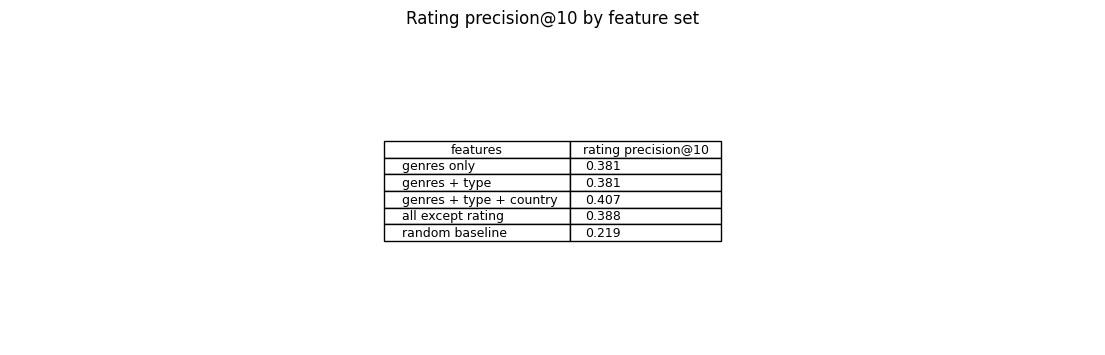

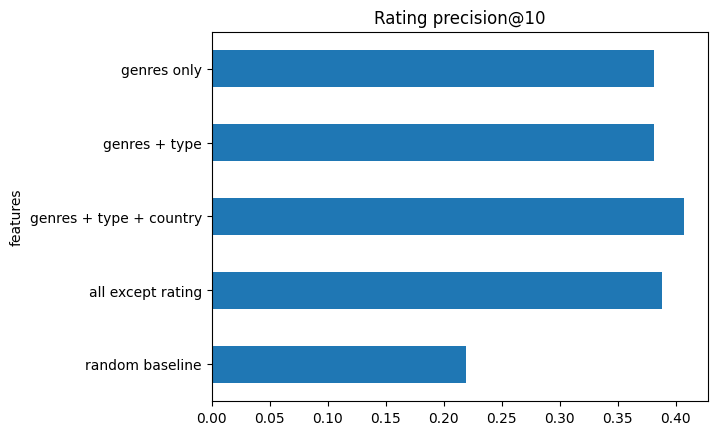

In [ ]:
save_table(results_df, '05_evaluation_table.png', 'Rating precision@10 by feature set')

results_df.set_index('features')['rating precision@10'].plot(kind='barh', title='Rating precision@10')
plt.gca().invert_yaxis()
plt.savefig('../screenshots/06_evaluation_chart.png', bbox_inches='tight')
plt.show()

## Phase 5 notes

**Results (rating precision@10, 300 random titles, rating hidden from the model)**
- Random baseline: 0.219
- Genres only: 0.381
- Genres + type: 0.381
- Genres + type + country: 0.407
- All except rating: 0.388

**1. What does a score above the baseline tell me, and what does it not tell me?**
Every version of the model scored well above the random baseline (0.38 to 0.41 against 0.219), so the recommendations are much more similar to the chosen title than random picks. This shows the features carry real signal, because the model never saw the rating but still found titles with a matching rating more often than chance. It does not tell me that the recommendations are good to watch or match the topic of the title, because rating is only one thing the titles can share. A kids' show and a mature drama differ in rating, so the test partly measures audience level.

**2. Which feature set did best, and why do I think so?**
Genres + type + country did best (0.407). Adding the country helped, probably because titles from the same country tend to have similar audience ratings. "Genres + type" scored the same as "genres only" (0.381), probably because the genre names already contain words like TV and Movies, so adding type gives almost no new information. Adding director and decade lowered the score a little (0.388), probably because they are very specific and add noise for this test.

In [ ]:
from sklearn.preprocessing import normalize

def recommend_for_user(liked_titles, n=10):
    found = [t for t in liked_titles if t.lower() in indices.index]
    missing = [t for t in liked_titles if t.lower() not in indices.index]
    if missing:
        print('Not found (skipped):', missing)
    if not found:
        return 'None of those titles were found.'

    idxs = [indices[t.lower()] for t in found]
    profile = np.asarray(matrix[idxs].mean(axis=0))
    profile = normalize(profile)
    scores = linear_kernel(profile, matrix).flatten()

    order = np.argsort(-scores, kind='stable')
    top = [j for j in order if j not in idxs][:n]
    result = df.loc[top, ['title', 'type', 'listed_in', 'rating']].copy()
    result['score'] = scores[top].round(3)
    return result

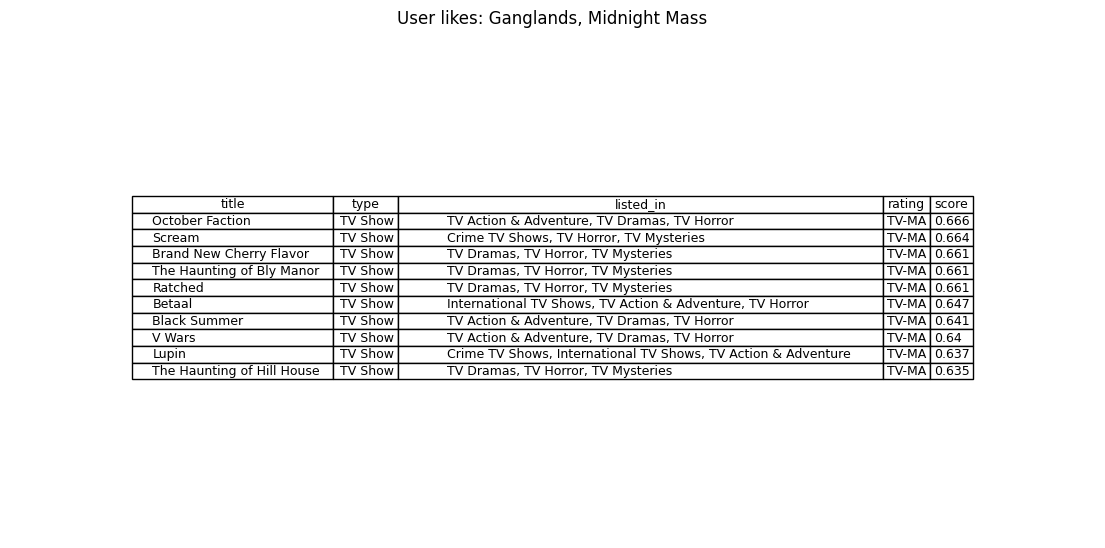

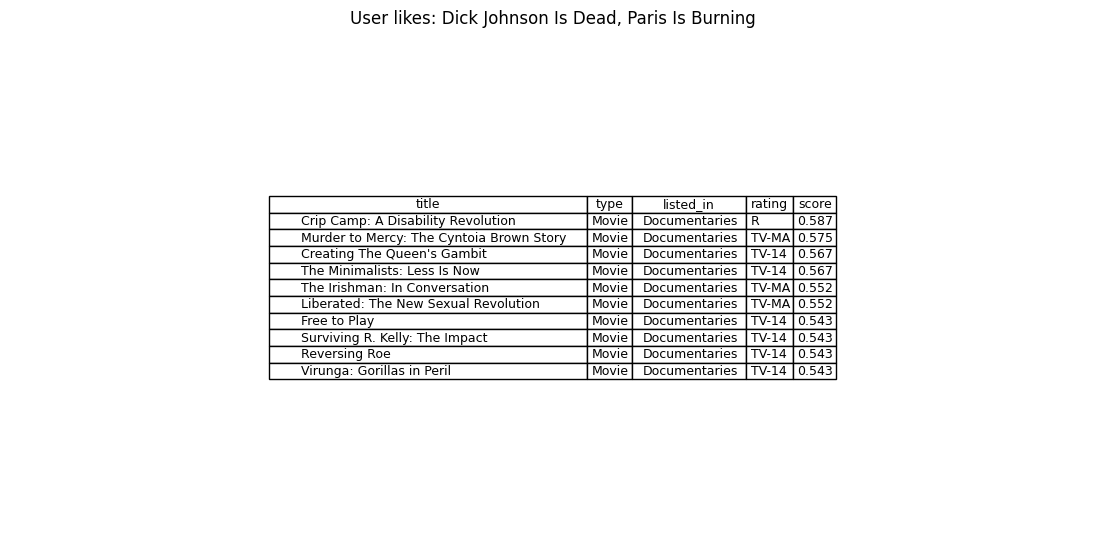

In [ ]:
tv_fan = recommend_for_user(['Ganglands', 'Midnight Mass'])
save_table(tv_fan, '07_user_tv_fan.png', 'User likes: Ganglands, Midnight Mass')

doc_fan = recommend_for_user(['Dick Johnson Is Dead', 'Paris Is Burning'])
save_table(doc_fan, '08_user_documentary_fan.png', 'User likes: Dick Johnson Is Dead, Paris Is Burning')

## Phase 6 notes

**1. How does recommend_for_user work?**
The function takes a list of titles the user likes and checks which ones exist in the data (missing ones are reported and skipped). It finds the row for each liked title and averages those rows into one "taste profile". It then scores that profile against every title using cosine similarity and sorts the scores from highest to lowest. Finally it removes all the titles the user already likes and returns the top 10 as a table.

**2. Why does averaging the vectors work as a "taste profile"?**
Each title is a row of numbers showing which features it has (genres, type, country and so on). Averaging the rows gives a new row that is partly like each liked title, so titles that share features with both end up closest to it. The results show this. For the user who likes Ganglands and Midnight Mass, all 10 recommendations are TV shows, all are rated TV-MA, and all include TV Horror, with most also tagged TV Dramas. These are the features the two liked titles have in common, so they dominate the average. For the user who likes Dick Johnson Is Dead and Paris Is Burning, all 10 recommendations are documentary movies.

**3. What are the limits of this personalisation?**
- The "user" is only a list of titles I type in. There is no real watch history, ratings, or time watched, so the profile shows what the titles have in common, not what a real person enjoys.
- The documentary results are matched on genre and format, not on topic. Crip Camp, Reversing Roe and The Minimalists are all documentaries, but they cover very different subjects. The model only knows the features in the data, so it can't tell a film about disability from one about minimalism.
- The scores are lower for the documentary user (0.54 to 0.59) than for the TV user (0.64 to 0.67). This is probably because the two liked documentaries are quite different from each other, so their average doesn't match any one title closely. When the liked titles are very different, the average can end up matching nothing well.
- The ratings in the documentary results are mixed (R, TV-MA, TV-14), so audience level is not matched as consistently as in the TV example.